In [3]:

from pathlib import Path
import pandas as pd
import numpy as np

PROJECT_DIR = Path.cwd().parent
DATA_PATH = PROJECT_DIR / "data" / "raw" / "train.csv"

print("Project folder:", PROJECT_DIR)
print("Dataset exists:", DATA_PATH.exists())


Project folder: d:\retail_sales_forecasting
Dataset exists: True


In [4]:

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())


Dataset loaded successfully!
Shape: (3000888, 6)
Columns: ['id', 'date', 'store_nbr', 'family', 'sales', 'onpromotion']


,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


In [5]:

print("Column names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()


Column names:
['id', 'date', 'store_nbr', 'family', 'sales', 'onpromotion']

Data types:
id               int64
date               str
store_nbr        int64
family             str
sales          float64
onpromotion      int64
dtype: object

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 3000888 entries, 0 to 3000887
Data columns (total 6 columns):
 #   Column       Dtype  
---  ------       -----  
 0   id           int64  
 1   date         str    
 2   store_nbr    int64  
 3   family       str    
 4   sales        float64
 5   onpromotion  int64  
dtypes: float64(1), int64(3), str(2)
memory usage: 137.4 MB


In [6]:

missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

print("\nTotal missing values:", df.isnull().sum().sum())


Missing values in each column:
id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64

Total missing values: 0


In [7]:

print("Exact duplicate rows:", df.duplicated().sum())


Exact duplicate rows: 0


In [8]:

df.describe()


,id,store_nbr,sales,onpromotion
count,3.000888e+06,3.000888e+06,3.000888e+06,3.000888e+06
mean,1.500444e+06,2.750000e+01,3.577757e+02,2.602770e+00
std,8.662819e+05,1.558579e+01,1.101998e+03,1.221888e+01
min,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00
25%,7.502218e+05,1.400000e+01,0.000000e+00,0.000000e+00
50%,1.500444e+06,2.750000e+01,1.100000e+01,0.000000e+00
75%,2.250665e+06,4.100000e+01,1.958473e+02,0.000000e+00
max,3.000887e+06,5.400000e+01,1.247170e+05,7.410000e+02


In [9]:
df.dtypes

id               int64
date               str
store_nbr        int64
family             str
sales          float64
onpromotion      int64
dtype: object

In [10]:
df.isnull().sum()

id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df.describe()

,id,store_nbr,sales,onpromotion
count,3.000888e+06,3.000888e+06,3.000888e+06,3.000888e+06
mean,1.500444e+06,2.750000e+01,3.577757e+02,2.602770e+00
std,8.662819e+05,1.558579e+01,1.101998e+03,1.221888e+01
min,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00
25%,7.502218e+05,1.400000e+01,0.000000e+00,0.000000e+00
50%,1.500444e+06,2.750000e+01,1.100000e+01,0.000000e+00
75%,2.250665e+06,4.100000e+01,1.958473e+02,0.000000e+00
max,3.000887e+06,5.400000e+01,1.247170e+05,7.410000e+02


In [13]:

# Convert date strings into actual datetime values
df["date"] = pd.to_datetime(df["date"])

print("First date:", df["date"].min())
print("Last date:", df["date"].max())

print("Unique dates:", df["date"].nunique())
print("Unique stores:", df["store_nbr"].nunique())
print("Unique product families:", df["family"].nunique())

print("\nDate data type:", df["date"].dtype)


First date: 2013-01-01 00:00:00
Last date: 2017-08-15 00:00:00
Unique dates: 1684
Unique stores: 54
Unique product families: 33

Date data type: datetime64[us]


In [14]:

from pathlib import Path

PROJECT_DIR = Path.cwd().parent
REPORT_DIR = PROJECT_DIR / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

quality_report = pd.DataFrame({
    "column": df.columns,
    "dtype": df.dtypes.astype(str).values,
    "missing_values": df.isnull().sum().values,
    "unique_values": df.nunique().values
})

quality_report.to_csv(
    REPORT_DIR / "data_quality_report.csv",
    index=False
)

display(quality_report)

print("Report saved successfully!")
print("Location:", REPORT_DIR / "data_quality_report.csv")


,column,dtype,missing_values,unique_values
0,id,int64,0,3000888
1,date,datetime64[us],0,1684
2,store_nbr,int64,0,54
3,family,str,0,33
4,sales,float64,0,379610
5,onpromotion,int64,0,362


Report saved successfully!
Location: d:\retail_sales_forecasting\reports\data_quality_report.csv


In [15]:

print(
    "Duplicate date-store-family combinations:",
    df.duplicated(
        subset=["date", "store_nbr", "family"]
    ).sum()
)


Duplicate date-store-family combinations: 0


In [16]:

# Convert date column into proper datetime format
df["date"] = pd.to_datetime(df["date"])

print("First date:", df["date"].min())
print("Last date:", df["date"].max())

print("Unique dates:", df["date"].nunique())
print("Unique stores:", df["store_nbr"].nunique())
print("Unique product families:", df["family"].nunique())

print("\nSales data type:", df["sales"].dtype)


First date: 2013-01-01 00:00:00
Last date: 2017-08-15 00:00:00
Unique dates: 1684
Unique stores: 54
Unique product families: 33

Sales data type: float64


In [17]:

from pathlib import Path

PROJECT_DIR = Path.cwd().parent
REPORT_DIR = PROJECT_DIR / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

quality_report = pd.DataFrame({
    "column": df.columns,
    "dtype": df.dtypes.astype(str).values,
    "missing_values": df.isnull().sum().values,
    "unique_values": df.nunique().values
})

quality_report.to_csv(
    REPORT_DIR / "data_quality_report.csv",
    index=False
)

display(quality_report)

print("Report saved at:", REPORT_DIR / "data_quality_report.csv")


,column,dtype,missing_values,unique_values
0,id,int64,0,3000888
1,date,datetime64[us],0,1684
2,store_nbr,int64,0,54
3,family,str,0,33
4,sales,float64,0,379610
5,onpromotion,int64,0,362


Report saved at: d:\retail_sales_forecasting\reports\data_quality_report.csv


## Daily Sales

In [18]:

daily_sales = (
    df.groupby("date", as_index=False)["sales"]
      .sum()
      .sort_values("date")
)

print("Daily sales shape:", daily_sales.shape)
display(daily_sales.head())


Daily sales shape: (1684, 2)


,date,sales
0,2013-01-01,2511.618999
1,2013-01-02,496092.417944
2,2013-01-03,361461.231124
3,2013-01-04,354459.677093
4,2013-01-05,477350.121229


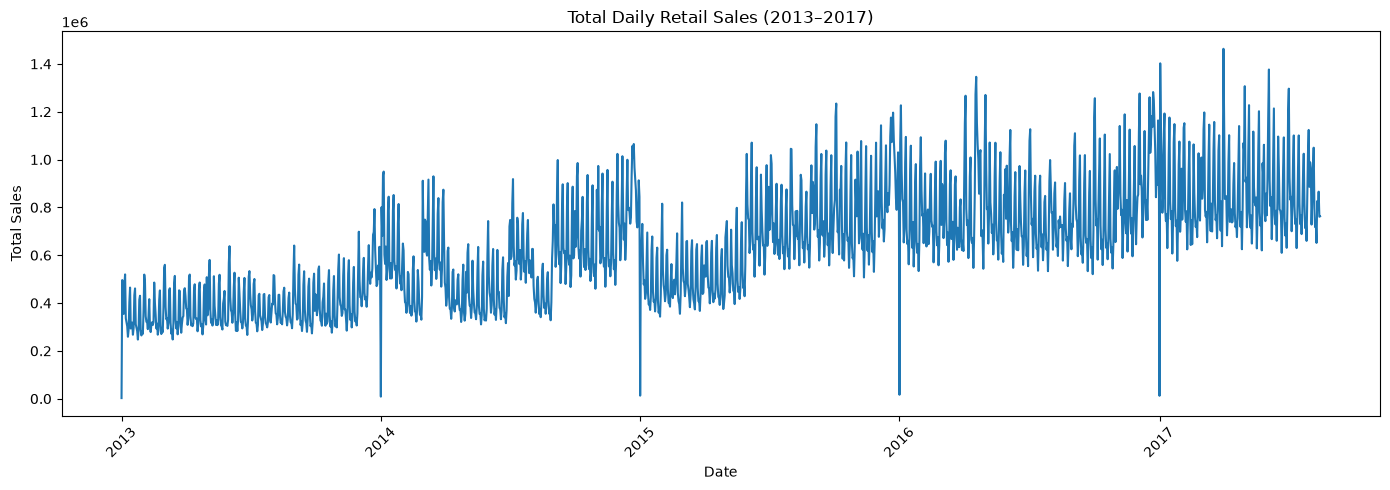

In [19]:

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))
plt.plot(daily_sales["date"], daily_sales["sales"])
plt.title("Total Daily Retail Sales (2013–2017)")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## Data Quality Check

In [20]:

# 1. Dataset size
print("Dataset shape:", df.shape)

# 2. Column names
print("\nColumns:")
print(df.columns.tolist())

# 3. Data types and non-null values
print("\nDataset information:")
df.info()

# 4. Missing values
print("\nMissing values:")
print(df.isnull().sum())

# 5. Exact duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# 6. Sales statistical summary
print("\nSales summary:")
print(df["sales"].describe())


Dataset shape: (3000888, 6)

Columns:
['id', 'date', 'store_nbr', 'family', 'sales', 'onpromotion']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 3000888 entries, 0 to 3000887
Data columns (total 6 columns):
 #   Column       Dtype         
---  ------       -----         
 0   id           int64         
 1   date         datetime64[us]
 2   store_nbr    int64         
 3   family       str           
 4   sales        float64       
 5   onpromotion  int64         
dtypes: datetime64[us](1), float64(1), int64(3), str(1)
memory usage: 137.4 MB

Missing values:
id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64

Duplicate rows: 0

Sales summary:
count    3.000888e+06
mean     3.577757e+02
std      1.101998e+03
min      0.000000e+00
25%      0.000000e+00
50%      1.100000e+01
75%      1.958473e+02
max      1.247170e+05
Name: sales, dtype: float64


### Sales distribution check

In [21]:

print("Missing values:")
print(df.isnull().sum().to_string())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nSales statistics:")
print(df["sales"].describe().to_string())

print("\nNegative sales:", (df["sales"] < 0).sum())
print("Zero sales:", (df["sales"] == 0).sum())


Missing values:
id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0

Duplicate rows:
0

Sales statistics:
count    3.000888e+06
mean     3.577757e+02
std      1.101998e+03
min      0.000000e+00
25%      0.000000e+00
50%      1.100000e+01
75%      1.958473e+02
max      1.247170e+05

Negative sales: 0
Zero sales: 939130


In [22]:

print(df["date"].dtype)
print(df["date"].head())


datetime64[us]
0   2013-01-01
1   2013-01-01
2   2013-01-01
3   2013-01-01
4   2013-01-01
Name: date, dtype: datetime64[us]


### Store-wise sales analysis

In [23]:

df["date"] = pd.to_datetime(df["date"])

print("Updated date type:", df["date"].dtype)
print("First date:", df["date"].min())
print("Last date:", df["date"].max())


Updated date type: datetime64[us]
First date: 2013-01-01 00:00:00
Last date: 2017-08-15 00:00:00


In [24]:

print("Unique stores:", df["store_nbr"].nunique())
print("Unique product families:", df["family"].nunique())
print("Unique dates:", df["date"].nunique())

print("\nDate range:")
print(df["date"].min(), "to", df["date"].max())


Unique stores: 54
Unique product families: 33
Unique dates: 1684

Date range:
2013-01-01 00:00:00 to 2017-08-15 00:00:00


In [25]:

store_sales = (
    df.groupby("store_nbr")["sales"]
    .sum()
    .sort_values(ascending=False)
)

print(store_sales.head(10).to_string())


store_nbr
44    6.208755e+07
45    5.449801e+07
47    5.094831e+07
3     5.048191e+07
49    4.342010e+07
46    4.189606e+07
48    3.593313e+07
51    3.291149e+07
8     3.049429e+07
50    2.865302e+07


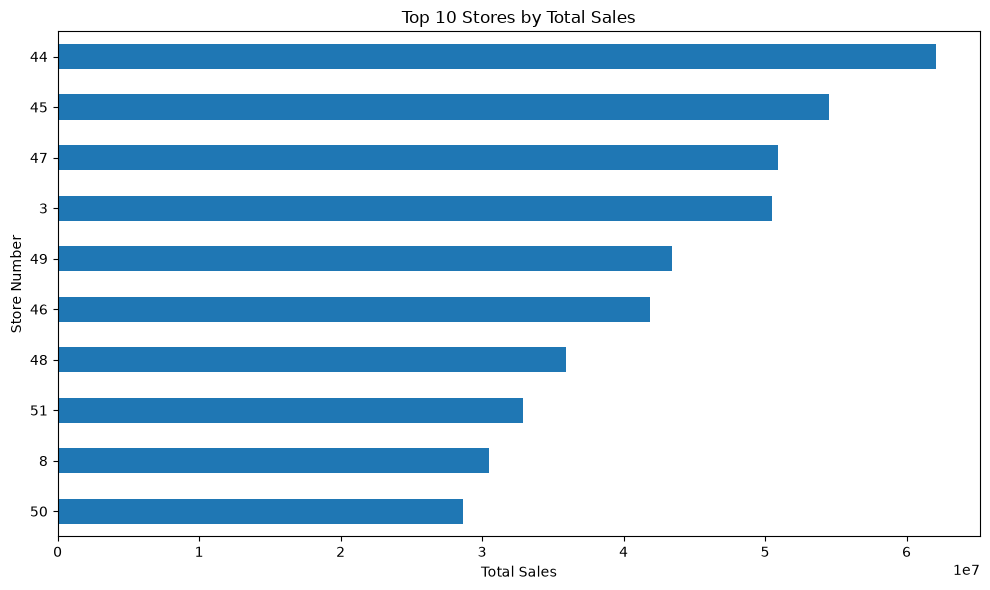

In [26]:

store_sales.head(10).sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 Stores by Total Sales")
plt.xlabel("Total Sales")
plt.ylabel("Store Number")
plt.tight_layout()
plt.show()


## Product Family Sales Analysis

In [27]:

family_sales = (
    df.groupby("family")["sales"]
    .sum()
    .sort_values(ascending=False)
)

print(family_sales.head(10).to_string())


family
GROCERY I        3.434627e+08
BEVERAGES        2.169545e+08
PRODUCE          1.227047e+08
CLEANING         9.752129e+07
DAIRY            6.448771e+07
BREAD/BAKERY     4.213395e+07
POULTRY          3.187600e+07
MEATS            3.108647e+07
PERSONAL CARE    2.459205e+07
DELI             2.411032e+07


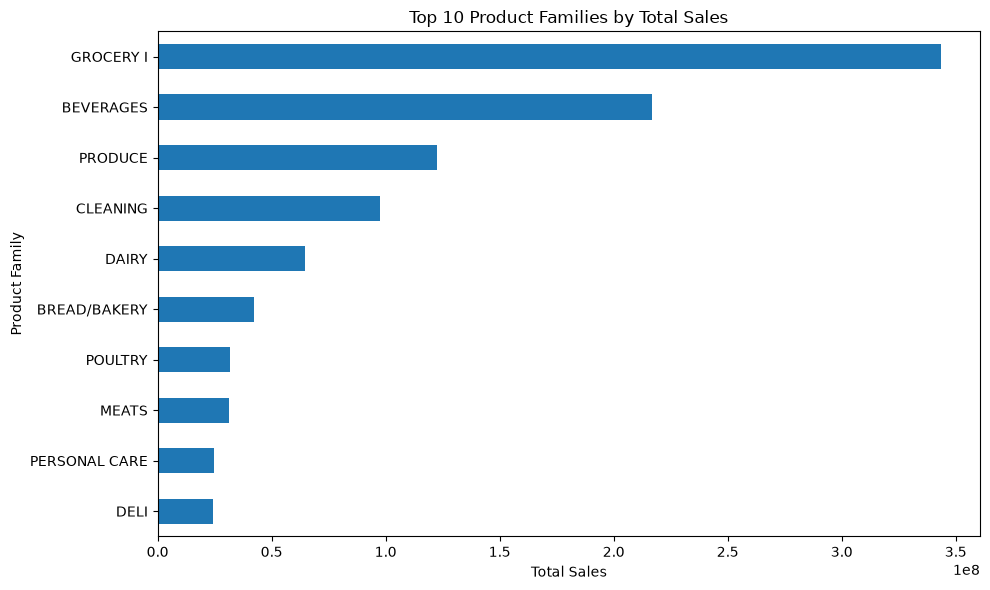

In [28]:

family_sales.head(10).sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 Product Families by Total Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product Family")
plt.tight_layout()
plt.show()


## Weekly Sales Trend

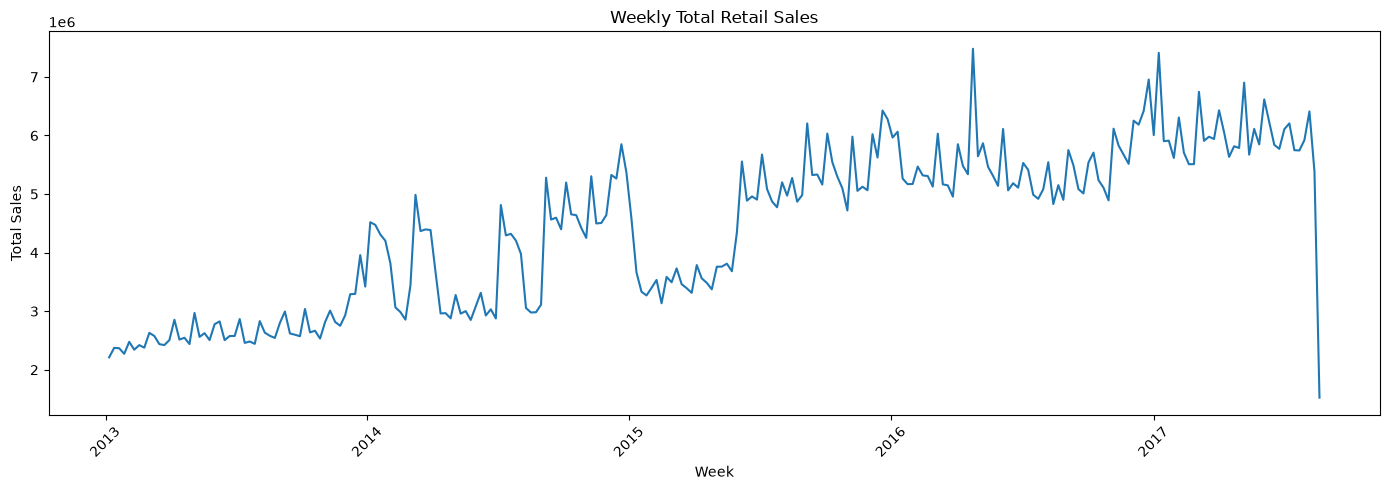

In [29]:

weekly_sales = (
    df.set_index("date")["sales"]
    .resample("W") 
    .sum()
)

plt.figure(figsize=(14, 5))
plt.plot(weekly_sales.index, weekly_sales.values)

plt.title("Weekly Total Retail Sales")
plt.xlabel("Week")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [30]:

daily_sales = (
    df.groupby("date", as_index=False)["sales"]
    .sum()
    .sort_values("date")
    .reset_index(drop=True)
)

print(daily_sales.head())
print("\nDataset shape:", daily_sales.shape)
print("\nDate range:")
print(daily_sales["date"].min(), "to", daily_sales["date"].max())


        date          sales
0 2013-01-01    2511.618999
1 2013-01-02  496092.417944
2 2013-01-03  361461.231124
3 2013-01-04  354459.677093
4 2013-01-05  477350.121229

Dataset shape: (1684, 2)

Date range:
2013-01-01 00:00:00 to 2017-08-15 00:00:00


In [31]:

split_index = int(len(daily_sales) * 0.8)

train_daily = daily_sales.iloc[:split_index].copy()
valid_daily = daily_sales.iloc[split_index:].copy()

print("Training period:")
print(train_daily["date"].min(), "to", train_daily["date"].max())

print("\nValidation period:")
print(valid_daily["date"].min(), "to", valid_daily["date"].max())

print("\nTraining rows:", len(train_daily))
print("Validation rows:", len(valid_daily))


Training period:
2013-01-01 00:00:00 to 2016-09-11 00:00:00

Validation period:
2016-09-12 00:00:00 to 2017-08-15 00:00:00

Training rows: 1347
Validation rows: 337


In [32]:

baseline_value = train_daily["sales"].mean()

valid_daily["baseline_prediction"] = baseline_value

print("Average daily sales:", baseline_value)
print(
    valid_daily[
        ["date", "sales", "baseline_prediction"]
    ].head()
)


Average daily sales: 584938.3346048518
           date          sales  baseline_prediction
1347 2016-09-12  678776.459126        584938.334605
1348 2016-09-13  603427.946974        584938.334605
1349 2016-09-14  624262.071976        584938.334605
1350 2016-09-15  568324.812986        584938.334605
1351 2016-09-16  691912.601466        584938.334605


In [33]:
daily_sales.shape

(1684, 2)

In [34]:
daily_sales.head()

,date,sales
0,2013-01-01,2511.618999
1,2013-01-02,496092.417944
2,2013-01-03,361461.231124
3,2013-01-04,354459.677093
4,2013-01-05,477350.121229


## Train Validation Split

In [35]:

# Make sure dates are sorted
daily_sales = daily_sales.sort_values("date").reset_index(drop=True)

# Use first 80% of dates for training
split_index = int(len(daily_sales) * 0.8)

train_daily = daily_sales.iloc[:split_index].copy()
valid_daily = daily_sales.iloc[split_index:].copy()

print("Training shape:", train_daily.shape)
print("Validation shape:", valid_daily.shape)

print("\nTraining period:")
print(train_daily["date"].min(), "to", train_daily["date"].max())

print("\nValidation period:")
print(valid_daily["date"].min(), "to", valid_daily["date"].max())


Training shape: (1347, 2)
Validation shape: (337, 2)

Training period:
2013-01-01 00:00:00 to 2016-09-11 00:00:00

Validation period:
2016-09-12 00:00:00 to 2017-08-15 00:00:00


## Baseline Forecast

In [36]:

# Average sales from training period
baseline_value = train_daily["sales"].mean()

# Predict the same average for each validation date
valid_daily["baseline_prediction"] = baseline_value

print("Average daily sales:", baseline_value)

print(
    valid_daily[
        ["date", "sales", "baseline_prediction"]
    ].head(10)
)


Average daily sales: 584938.3346048518
           date         sales  baseline_prediction
1347 2016-09-12  6.787765e+05        584938.334605
1348 2016-09-13  6.034279e+05        584938.334605
1349 2016-09-14  6.242621e+05        584938.334605
1350 2016-09-15  5.683248e+05        584938.334605
1351 2016-09-16  6.919126e+05        584938.334605
1352 2016-09-17  8.992193e+05        584938.334605
1353 2016-09-18  1.018663e+06        584938.334605
1354 2016-09-19  6.811593e+05        584938.334605
1355 2016-09-20  6.509803e+05        584938.334605
1356 2016-09-21  6.669284e+05        584938.334605


In [37]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(
    valid_daily["sales"],
    valid_daily["baseline_prediction"]
)

rmse = np.sqrt(
    mean_squared_error(
        valid_daily["sales"],
        valid_daily["baseline_prediction"]
    )
)

print("Baseline MAE:", round(mae, 2))
print("Baseline RMSE:", round(rmse, 2))


Baseline MAE: 267597.91
Baseline RMSE: 321869.46


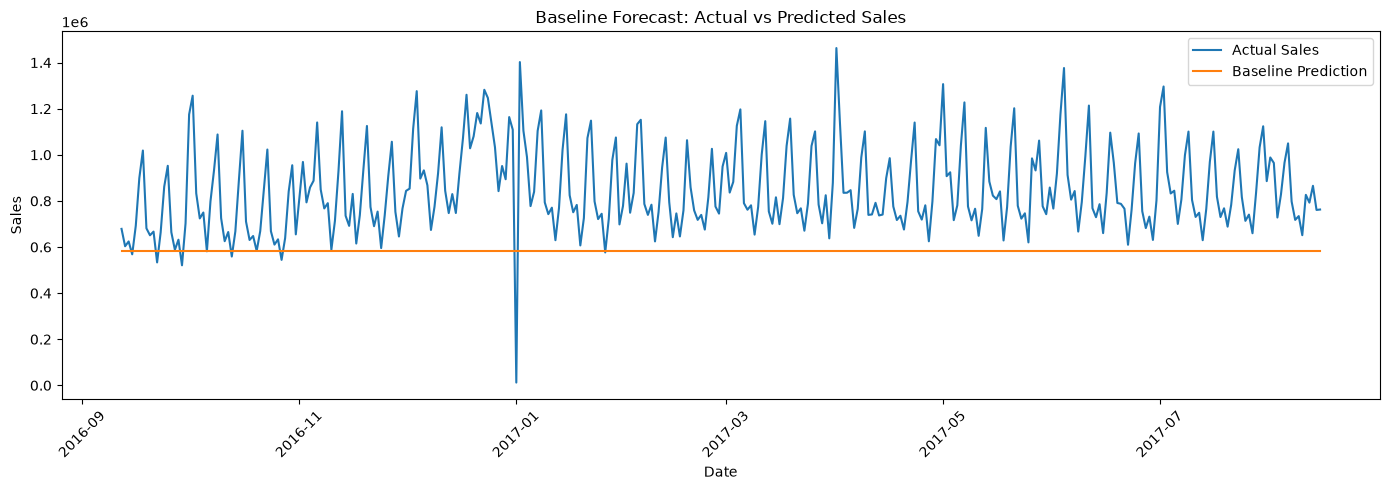

In [38]:

plt.figure(figsize=(14, 5))

plt.plot(
    valid_daily["date"],
    valid_daily["sales"],
    label="Actual Sales"
)

plt.plot(
    valid_daily["date"],
    valid_daily["baseline_prediction"],
    label="Baseline Prediction"
)

plt.title("Baseline Forecast: Actual vs Predicted Sales")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## Feature Engineering

In [39]:

# Start from daily sales data
model_df = daily_sales.copy()

# Calendar features
model_df["day_of_week"] = model_df["date"].dt.dayofweek
model_df["month"] = model_df["date"].dt.month
model_df["day_of_month"] = model_df["date"].dt.day

# Past sales features
model_df["lag_1"] = model_df["sales"].shift(1)
model_df["lag_7"] = model_df["sales"].shift(7)
model_df["lag_14"] = model_df["sales"].shift(14)

# Rolling average of the PREVIOUS 7 days
model_df["rolling_mean_7"] = (
    model_df["sales"].shift(1).rolling(window=7).mean()
)

# Remove rows without enough historical data
model_df = model_df.dropna().reset_index(drop=True)

print("Model dataset shape:", model_df.shape)
print("\nFirst 5 rows:")
print(model_df.head().to_string(index=False))


Model dataset shape: (1670, 9)

First 5 rows:
      date         sales  day_of_week  month  day_of_month         lag_1         lag_7        lag_14  rolling_mean_7
2013-01-15 299129.549954            1      1            15 293348.362078 318347.777981   2511.618999   332977.628174
2013-01-16 318347.913946            2      1            16 299129.549954 302530.809018 496092.417944   330232.167027
2013-01-17 267498.515975            3      1            17 318347.913946 258982.003049 361461.231124   332491.753446
2013-01-18 296130.850028            4      1            18 267498.515975 289737.685085 354459.677093   333708.398150
2013-01-19 432459.852021            5      1            19 296130.850028 403258.212011 477350.121229   334621.707427


In [40]:

# Use the original validation start date
validation_start = valid_daily["date"].min()

# Separate past training data and later validation data
train_model = model_df[model_df["date"] < validation_start].copy()
valid_model = model_df[model_df["date"] >= validation_start].copy()

features = [
    "day_of_week",
    "month",
    "day_of_month",
    "lag_1",
    "lag_7",
    "lag_14",
    "rolling_mean_7"
]

X_train = train_model[features]
y_train = train_model["sales"]

X_valid = valid_model[features]
y_valid = valid_model["sales"]

print("Training rows:", len(X_train))
print("Validation rows:", len(X_valid))
print("Validation starts:", valid_model["date"].min())
print("Validation ends:", valid_model["date"].max())


Training rows: 1333
Validation rows: 337
Validation starts: 2016-09-12 00:00:00
Validation ends: 2017-08-15 00:00:00


In [41]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

rf_model = RandomForestRegressor(
    n_estimators=200,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

predictions = rf_model.predict(X_valid)

mae_rf = mean_absolute_error(y_valid, predictions)
rmse_rf = np.sqrt(mean_squared_error(y_valid, predictions))

print("Random Forest MAE:", round(mae_rf, 2))
print("Random Forest RMSE:", round(rmse_rf, 2))


Random Forest MAE: 77640.95
Random Forest RMSE: 122620.0


In [42]:

print("BASELINE")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))

print("\nRANDOM FOREST")
print("MAE:", round(mae_rf, 2))
print("RMSE:", round(rmse_rf, 2))

if mae_rf < mae:
    print("\nRandom Forest has lower MAE than baseline.")
else:
    print("\nRandom Forest did not improve MAE over baseline.")


BASELINE
MAE: 267597.91
RMSE: 321869.46

RANDOM FOREST
MAE: 77640.95
RMSE: 122620.0

Random Forest has lower MAE than baseline.


## Model Evaluation (Actual vs Predicted)

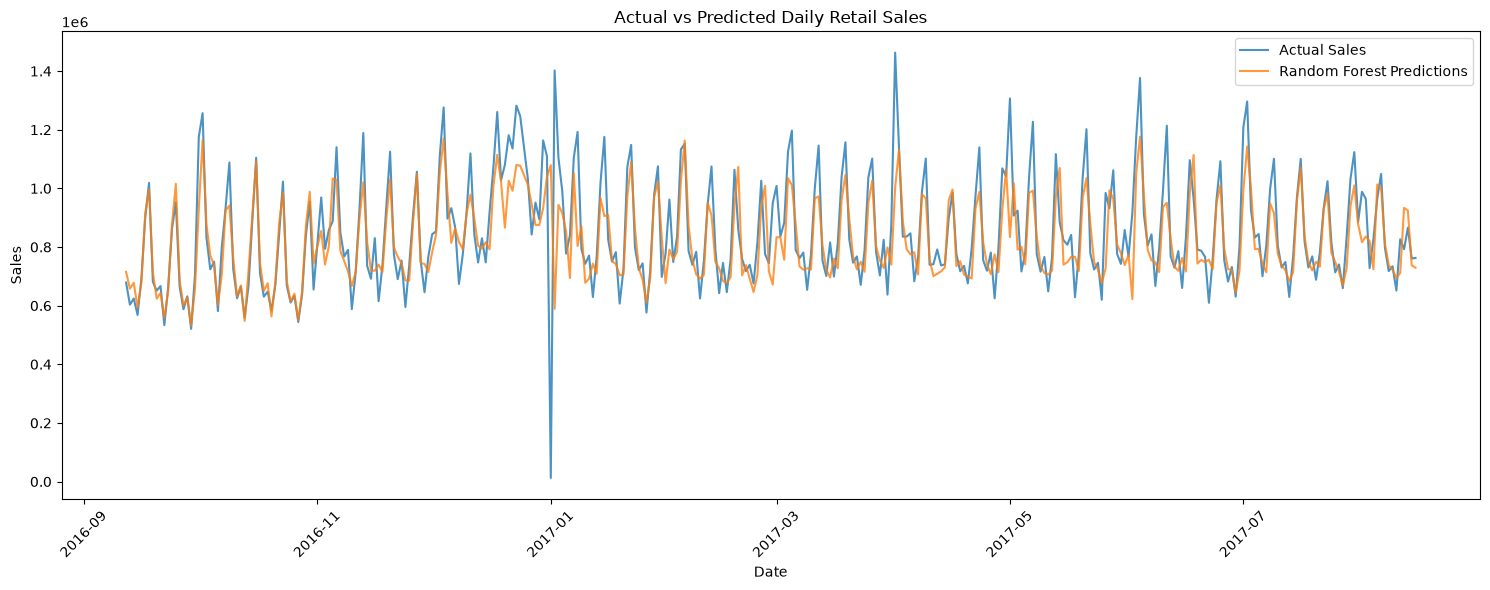

In [43]:

plt.figure(figsize=(15, 6))

plt.plot(
    valid_model["date"],
    y_valid,
    label="Actual Sales",
    alpha=0.8
)

plt.plot(
    valid_model["date"],
    predictions,
    label="Random Forest Predictions",
    alpha=0.8
)

plt.title("Actual vs Predicted Daily Retail Sales")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


       Feature  Importance
         lag_7    0.523536
rolling_mean_7    0.125100
        lag_14    0.115749
         lag_1    0.105073
   day_of_week    0.069065
  day_of_month    0.047107
         month    0.014369


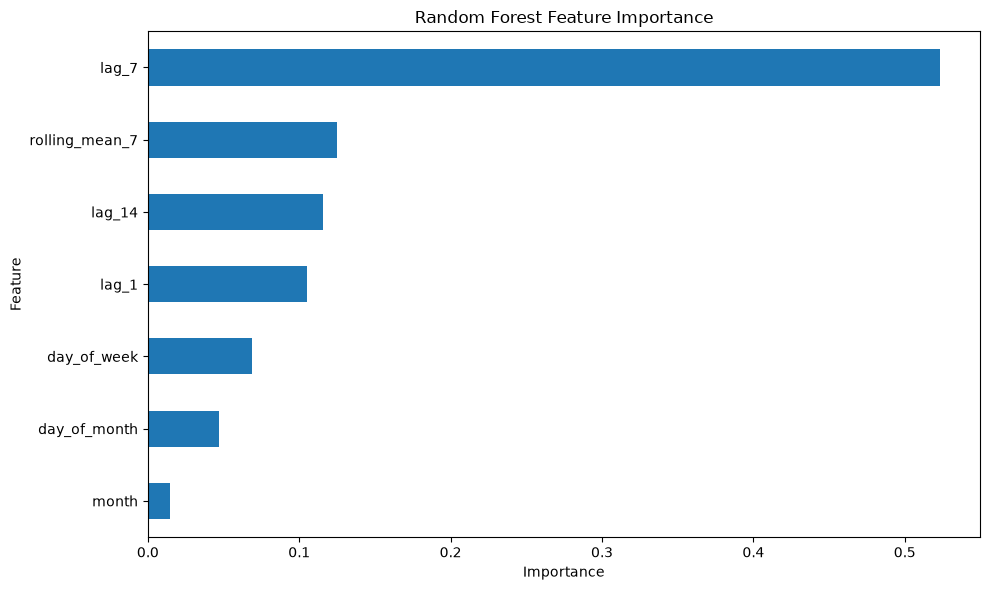

In [44]:

importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=True
)

print(importance_df.sort_values(
    "Importance",
    ascending=False
).to_string(index=False))

importance_df.plot(
    x="Feature",
    y="Importance",
    kind="barh",
    figsize=(10, 6),
    legend=False
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [45]:

results = valid_model[["date", "sales"]].copy()

results["predicted_sales"] = predictions

results["absolute_error"] = (
    results["sales"] - results["predicted_sales"]
).abs()

print(
    results.sort_values(
        "absolute_error",
        ascending=False
    ).head(10).to_string(index=False)
)


      date        sales  predicted_sales  absolute_error
2017-01-01 1.208250e+04     1.079380e+06    1.067297e+06
2017-01-02 1.402306e+06     5.894034e+05    8.129029e+05
2017-05-01 1.306699e+06     8.339900e+05    4.727094e+05
2017-04-01 1.463084e+06     1.003493e+06    4.595907e+05
2017-01-08 1.192544e+06     8.031829e+05    3.893608e+05
2017-06-02 9.184213e+05     6.222294e+05    2.961919e+05
2017-02-28 9.493668e+05     6.717463e+05    2.776206e+05
2017-01-15 1.175725e+06     9.053348e+05    2.703903e+05
2017-06-11 1.213674e+06     9.508367e+05    2.628373e+05
2017-05-26 9.845112e+05     7.264449e+05    2.580662e+05


## Investigating Large Prediction Errors

In [46]:

# Check sales around the largest error dates
for date in ["2017-01-01", "2017-01-02",
             "2017-04-01", "2017-05-01"]:

    target_date = pd.Timestamp(date)

    mask = (
        (daily_sales["date"] >= target_date - pd.Timedelta(days=3))
        & (daily_sales["date"] <= target_date + pd.Timedelta(days=3))
    )

    print(f"\nSales around {date}:")
    print(daily_sales.loc[mask].to_string(index=False))



Sales around 2017-01-01:
      date        sales
2016-12-29 8.941082e+05
2016-12-30 1.163643e+06
2016-12-31 1.109013e+06
2017-01-01 1.208250e+04
2017-01-02 1.402306e+06
2017-01-03 1.104377e+06
2017-01-04 9.900935e+05

Sales around 2017-01-02:
      date        sales
2016-12-30 1.163643e+06
2016-12-31 1.109013e+06
2017-01-01 1.208250e+04
2017-01-02 1.402306e+06
2017-01-03 1.104377e+06
2017-01-04 9.900935e+05
2017-01-05 7.776210e+05

Sales around 2017-04-01:
      date        sales
2017-03-29 8.246330e+05
2017-03-30 6.376243e+05
2017-03-31 8.787500e+05
2017-04-01 1.463084e+06
2017-04-02 1.138650e+06
2017-04-03 8.351916e+05
2017-04-04 8.356026e+05

Sales around 2017-05-01:
      date        sales
2017-04-28 7.976366e+05
2017-04-29 1.068280e+06
2017-04-30 1.041249e+06
2017-05-01 1.306699e+06
2017-05-02 9.073241e+05
2017-05-03 9.242473e+05
2017-05-04 7.166546e+05


In [47]:

check_dates = ["01-01", "01-02", "04-01", "05-01"]

temp = daily_sales.copy()
temp["month_day"] = temp["date"].dt.strftime("%m-%d")
temp["year"] = temp["date"].dt.year

for md in check_dates:
    print(f"\nSales on {md} across years:")
    print(
        temp.loc[temp["month_day"] == md,
                 ["date", "sales"]]
        .sort_values("date")
        .to_string(index=False)
    )



Sales on 01-01 across years:
      date        sales
2013-01-01  2511.618999
2014-01-01  8602.065404
2015-01-01 12773.616980
2016-01-01 16433.394000
2017-01-01 12082.500997

Sales on 01-02 across years:
      date        sales
2013-01-02 4.960924e+05
2014-01-02 8.010112e+05
2015-01-02 6.577634e+05
2016-01-02 1.066677e+06
2017-01-02 1.402306e+06

Sales on 04-01 across years:
      date        sales
2013-04-01 4.288164e+05
2014-04-01 4.850799e+05
2015-04-01 5.572232e+05
2016-04-01 8.724673e+05
2017-04-01 1.463084e+06

Sales on 05-01 across years:
      date        sales
2013-05-01 5.079746e+05
2014-05-01 5.303808e+05
2015-05-01 6.745094e+05
2016-05-01 1.270121e+06
2017-05-01 1.306699e+06


In [48]:

error_analysis = valid_model[["date", "sales"]].copy()
error_analysis["prediction"] = predictions

error_analysis["absolute_error"] = (
    error_analysis["sales"] - error_analysis["prediction"]
).abs()

error_analysis["weekday"] = (
    error_analysis["date"].dt.day_name()
)

weekday_errors = (
    error_analysis.groupby("weekday")["absolute_error"]
    .mean()
    .sort_values(ascending=False)
)

print(weekday_errors.to_string())


weekday
Sunday       138913.071893
Friday        77889.818379
Saturday      77328.855186
Monday        73524.185584
Thursday      62927.196314
Wednesday     62611.954506
Tuesday       52184.171243


## Holiday Feature Engineering

In [49]:

holidays_path = PROJECT_DIR / "data" / "raw" / "holidays_events.csv"

holidays = pd.read_csv(holidays_path)

print("Shape:", holidays.shape)
print("Columns:", holidays.columns.tolist())
print(holidays.head(10).to_string(index=False))


Shape: (350, 6)
Columns: ['date', 'type', 'locale', 'locale_name', 'description', 'transferred']
      date    type   locale locale_name                   description  transferred
2012-03-02 Holiday    Local       Manta            Fundacion de Manta        False
2012-04-01 Holiday Regional    Cotopaxi Provincializacion de Cotopaxi        False
2012-04-12 Holiday    Local      Cuenca           Fundacion de Cuenca        False
2012-04-14 Holiday    Local    Libertad     Cantonizacion de Libertad        False
2012-04-21 Holiday    Local    Riobamba     Cantonizacion de Riobamba        False
2012-05-12 Holiday    Local        Puyo        Cantonizacion del Puyo        False
2012-06-23 Holiday    Local    Guaranda     Cantonizacion de Guaranda        False
2012-06-25 Holiday Regional    Imbabura Provincializacion de Imbabura        False
2012-06-25 Holiday    Local   Latacunga    Cantonizacion de Latacunga        False
2012-06-25 Holiday    Local     Machala          Fundacion de Machala    

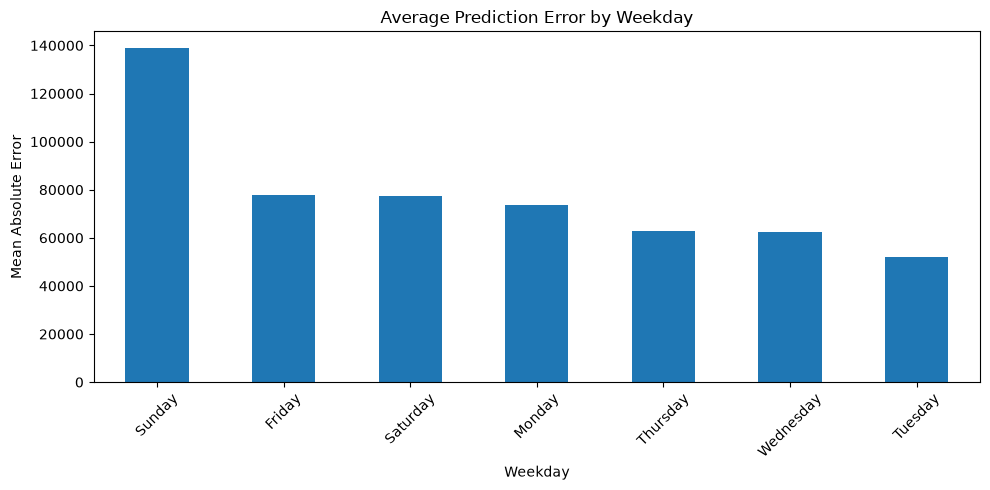

In [50]:

weekday_errors.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Average Prediction Error by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Mean Absolute Error")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## Investigate Unusual Sales Patterns

In [51]:
# Load the holidays and events dataset

holidays_path = PROJECT_DIR / "data" / "raw" / "holidays_events.csv"

holidays = pd.read_csv(holidays_path)

print("Dataset shape:", holidays.shape)
print("\nColumn names:")
print(holidays.columns.tolist())

print("\nFirst 10 rows:")
display(holidays.head(10))

Dataset shape: (350, 6)

Column names:
['date', 'type', 'locale', 'locale_name', 'description', 'transferred']

First 10 rows:


,date,type,locale,locale_name,description,transferred
0,2012-03-02,Holiday,Local,Manta,Fundacion de Manta,False
1,2012-04-01,Holiday,Regional,Cotopaxi,Provincializacion de Cotopaxi,False
2,2012-04-12,Holiday,Local,Cuenca,Fundacion de Cuenca,False
3,2012-04-14,Holiday,Local,Libertad,Cantonizacion de Libertad,False
4,2012-04-21,Holiday,Local,Riobamba,Cantonizacion de Riobamba,False
5,2012-05-12,Holiday,Local,Puyo,Cantonizacion del Puyo,False
6,2012-06-23,Holiday,Local,Guaranda,Cantonizacion de Guaranda,False
7,2012-06-25,Holiday,Regional,Imbabura,Provincializacion de Imbabura,False
8,2012-06-25,Holiday,Local,Latacunga,Cantonizacion de Latacunga,False
9,2012-06-25,Holiday,Local,Machala,Fundacion de Machala,False


## Inspect Holiday Types and Event Coverage

In [52]:
# 1. Convert holiday dates to datetime format
holidays["date"] = pd.to_datetime(holidays["date"])

# 2. Check the date range
print("First holiday date:", holidays["date"].min())
print("Last holiday date:", holidays["date"].max())

# 3. Count different event types
print("\nEvent types:")
display(holidays["type"].value_counts().to_frame("count"))

# 4. Check geographic scopes
print("\nGeographic scopes:")
display(holidays["locale"].value_counts().to_frame("count"))

# 5. Check transferred and non-transferred events
print("\nTransferred status:")
display(holidays["transferred"].value_counts().to_frame("count"))

# 6. Inspect transferred events
print("\nTransferred event records:")
display(
    holidays.loc[holidays["transferred"] == True]
    .sort_values("date")
    .head(15)
)

# 7. Check how many events occur on each date
events_per_date = holidays.groupby("date").size()

print("\nDates with multiple event records:", (events_per_date > 1).sum())
print("Maximum events recorded on one date:", events_per_date.max())

First holiday date: 2012-03-02 00:00:00
Last holiday date: 2017-12-26 00:00:00

Event types:


,count
type,
Holiday,221
Event,56
Additional,51
Transfer,12
Bridge,5
Work Day,5



Geographic scopes:


,count
locale,
National,174
Local,152
Regional,24



Transferred status:


,count
transferred,
False,338
True,12



Transferred event records:


,date,type,locale,locale_name,description,transferred
19,2012-10-09,Holiday,National,Ecuador,Independencia de Guayaquil,True
72,2013-10-09,Holiday,National,Ecuador,Independencia de Guayaquil,True
135,2014-10-09,Holiday,National,Ecuador,Independencia de Guayaquil,True
255,2016-05-24,Holiday,National,Ecuador,Batalla de Pichincha,True
266,2016-07-25,Holiday,Local,Guayaquil,Fundacion de Guayaquil,True
268,2016-08-10,Holiday,National,Ecuador,Primer Grito de Independencia,True
297,2017-01-01,Holiday,National,Ecuador,Primer dia del ano,True
303,2017-04-12,Holiday,Local,Cuenca,Fundacion de Cuenca,True
312,2017-05-24,Holiday,National,Ecuador,Batalla de Pichincha,True
324,2017-08-10,Holiday,National,Ecuador,Primer Grito de Independencia,True



Dates with multiple event records: 31
Maximum events recorded on one date: 4


## Daily Holiday Features

In [53]:
# Create a working copy of the holiday dataset
holiday_work = holidays.copy()

# Keep records that represent events on their listed dates.
# Transferred=True records refer to holidays moved from their original dates.
active_holidays = holiday_work.loc[
    holiday_work["transferred"] == False
].copy()

# For this first model improvement, focus on national events.
national_events = active_holidays.loc[
    active_holidays["locale"] == "National"
].copy()

# Define separate daily indicator features for each event type
event_types = [
    "Holiday",
    "Transfer",
    "Event",
    "Additional",
    "Bridge",
    "Work Day"
]

# Create a date-level feature table
holiday_features = pd.DataFrame({
    "date": daily_sales["date"].drop_duplicates().sort_values()
})

for event_type in event_types:
    feature_name = "is_national_" + event_type.lower().replace(" ", "_")

    event_dates = national_events.loc[
        national_events["type"] == event_type, "date"
    ].drop_duplicates()

    holiday_features[feature_name] = (
        holiday_features["date"].isin(event_dates).astype(int)
    )

# Check the resulting features
print("Holiday feature table shape:", holiday_features.shape)

print("\nNumber of dates flagged for each feature:")
display(
    holiday_features.drop(columns="date").sum()
    .sort_values(ascending=False)
    .to_frame("number_of_dates")
)

print("\nSample dates with at least one national event:")
display(
    holiday_features.loc[
        holiday_features.drop(columns="date").sum(axis=1) > 0
    ].head(15)
)

Holiday feature table shape: (1684, 7)

Number of dates flagged for each feature:


,number_of_dates
is_national_event,55
is_national_holiday,40
is_national_additional,29
is_national_transfer,7
is_national_work_day,5
is_national_bridge,3



Sample dates with at least one national event:


,date,is_national_holiday,is_national_transfer,is_national_event,is_national_additional,is_national_bridge,is_national_work_day
0,2013-01-01,1,0,0,0,0,0
4,2013-01-05,0,0,0,0,0,1
11,2013-01-12,0,0,0,0,0,1
41,2013-02-11,1,0,0,0,0,0
42,2013-02-12,1,0,0,0,0,0
118,2013-04-29,1,0,0,0,0,0
120,2013-05-01,1,0,0,0,0,0
130,2013-05-11,0,0,0,1,0,0
131,2013-05-12,0,0,1,0,0,0
143,2013-05-24,1,0,0,0,0,0


## Merge Holiday Features with Daily Sales

In [54]:
# Merge holiday indicators into the daily sales data
daily_sales_holidays = daily_sales.merge(
    holiday_features,
    on="date",
    how="left",
    validate="one_to_one"
)

# Fill missing event indicators with 0
holiday_columns = [
    col for col in holiday_features.columns if col != "date"
]

daily_sales_holidays[holiday_columns] = (
    daily_sales_holidays[holiday_columns].fillna(0).astype(int)
)

# Validate the merge
print("Original daily sales shape:", daily_sales.shape)
print("Merged dataset shape:", daily_sales_holidays.shape)

print(
    "Duplicate dates after merge:",
    daily_sales_holidays["date"].duplicated().sum()
)

print("\nSample merged data:")
display(daily_sales_holidays.head())

Original daily sales shape: (1684, 2)
Merged dataset shape: (1684, 8)
Duplicate dates after merge: 0

Sample merged data:


,date,sales,is_national_holiday,is_national_transfer,is_national_event,is_national_additional,is_national_bridge,is_national_work_day
0,2013-01-01,2511.618999,1,0,0,0,0,0
1,2013-01-02,496092.417944,0,0,0,0,0,0
2,2013-01-03,361461.231124,0,0,0,0,0,0
3,2013-01-04,354459.677093,0,0,0,0,0,0
4,2013-01-05,477350.121229,0,0,0,0,0,1


## Building an Improved Random Forest Model


In [55]:
# Create a new modelling dataset with holiday features
model_df_holidays = daily_sales_holidays.copy()

# Calendar features
model_df_holidays["day_of_week"] = (
    model_df_holidays["date"].dt.dayofweek
)
model_df_holidays["month"] = (
    model_df_holidays["date"].dt.month
)
model_df_holidays["day_of_month"] = (
    model_df_holidays["date"].dt.day
)

# Lag features based only on previous days' sales
model_df_holidays["lag_1"] = (
    model_df_holidays["sales"].shift(1)
)
model_df_holidays["lag_7"] = (
    model_df_holidays["sales"].shift(7)
)
model_df_holidays["lag_14"] = (
    model_df_holidays["sales"].shift(14)
)

# Rolling mean of the previous 7 days
model_df_holidays["rolling_mean_7"] = (
    model_df_holidays["sales"].shift(1).rolling(window=7).mean()
)

# Remove rows with missing lag/rolling values
model_df_holidays = (
    model_df_holidays.dropna().reset_index(drop=True)
)

print("Updated modelling dataset shape:", model_df_holidays.shape)
display(model_df_holidays.head())

Updated modelling dataset shape: (1670, 15)


,date,sales,is_national_holiday,is_national_transfer,is_national_event,is_national_additional,is_national_bridge,is_national_work_day,day_of_week,month,day_of_month,lag_1,lag_7,lag_14,rolling_mean_7
0,2013-01-15,299129.549954,0,0,0,0,0,0,1,1,15,293348.362078,318347.777981,2511.618999,332977.628174
1,2013-01-16,318347.913946,0,0,0,0,0,0,2,1,16,299129.549954,302530.809018,496092.417944,330232.167027
2,2013-01-17,267498.515975,0,0,0,0,0,0,3,1,17,318347.913946,258982.003049,361461.231124,332491.753446
3,2013-01-18,296130.850028,0,0,0,0,0,0,4,1,18,267498.515975,289737.685085,354459.677093,333708.398150
4,2013-01-19,432459.852021,0,0,0,0,0,0,5,1,19,296130.850028,403258.212011,477350.121229,334621.707427


In [56]:
# Use the same validation start date as the original model
validation_start = valid_daily["date"].min()

train_model_holidays = model_df_holidays[
    model_df_holidays["date"] < validation_start
].copy()

valid_model_holidays = model_df_holidays[
    model_df_holidays["date"] >= validation_start
].copy()

# Select original features plus holiday indicators
holiday_columns = [
    "is_national_holiday",
    "is_national_transfer",
    "is_national_event",
    "is_national_additional",
    "is_national_bridge",
    "is_national_work_day"
]

features_holidays = [
    "day_of_week",
    "month",
    "day_of_month",
    "lag_1",
    "lag_7",
    "lag_14",
    "rolling_mean_7"
] + holiday_columns

X_train_holidays = train_model_holidays[features_holidays]
y_train_holidays = train_model_holidays["sales"]

X_valid_holidays = valid_model_holidays[features_holidays]
y_valid_holidays = valid_model_holidays["sales"]

print("Training rows:", len(X_train_holidays))
print("Validation rows:", len(X_valid_holidays))
print("Features:", len(features_holidays))

Training rows: 1333
Validation rows: 337
Features: 13


In [57]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

rf_holiday_model = RandomForestRegressor(
    n_estimators=200,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_holiday_model.fit(X_train_holidays, y_train_holidays)

predictions_holidays = rf_holiday_model.predict(X_valid_holidays)

mae_holiday = mean_absolute_error(
    y_valid_holidays, predictions_holidays
)

rmse_holiday = np.sqrt(
    mean_squared_error(y_valid_holidays, predictions_holidays)
)

print(f"Random Forest with holidays MAE: {mae_holiday:,.2f}")
print(f"Random Forest with holidays RMSE: {rmse_holiday:,.2f}")

Random Forest with holidays MAE: 77,083.00
Random Forest with holidays RMSE: 122,154.26


## Model Comparison

In [58]:
comparison = pd.DataFrame({
    "Model": [
        "Baseline",
        "Random Forest",
        "Random Forest + Holiday Features"
    ],
    "MAE": [
        267597.91,
        mae_rf,
        mae_holiday
    ],
    "RMSE": [
        321869.46,
        rmse_rf,
        rmse_holiday
    ]
})

display(comparison.round(2))

,Model,MAE,RMSE
0,Baseline,267597.91,321869.46
1,Random Forest,77640.95,122620.00
2,Random Forest + Holiday Features,77083.00,122154.26


## Model Performance Comparison

The original Random Forest model achieved an MAE of 77,640.95 and an RMSE of 122,620.00.

After adding national holiday and event indicators, the updated model achieved an MAE of 77,083.00 and an RMSE of 122,154.26.

This represents a modest improvement of approximately 0.72% in MAE and 0.38% in RMSE compared with the original Random Forest model.

The results suggest that the selected holiday features provide some additional predictive information, although their overall contribution is limited. Further validation is needed before concluding that the improvement generalizes to other forecasting periods.

## Feature Importance of the Improved Model

I examine feature importance scores from the Random Forest model trained with holiday indicators.

This analysis helps compare the contribution of historical sales features, calendar features, and national event indicators. Feature importance reflects the model's predictive reliance on inputs and should not be interpreted as causal evidence.

,feature,importance
4,lag_7,0.522349
6,rolling_mean_7,0.124126
5,lag_14,0.114632
3,lag_1,0.104433
0,day_of_week,0.068612
2,day_of_month,0.044655
1,month,0.012724
7,is_national_holiday,0.003901
10,is_national_additional,0.003356
9,is_national_event,0.001007


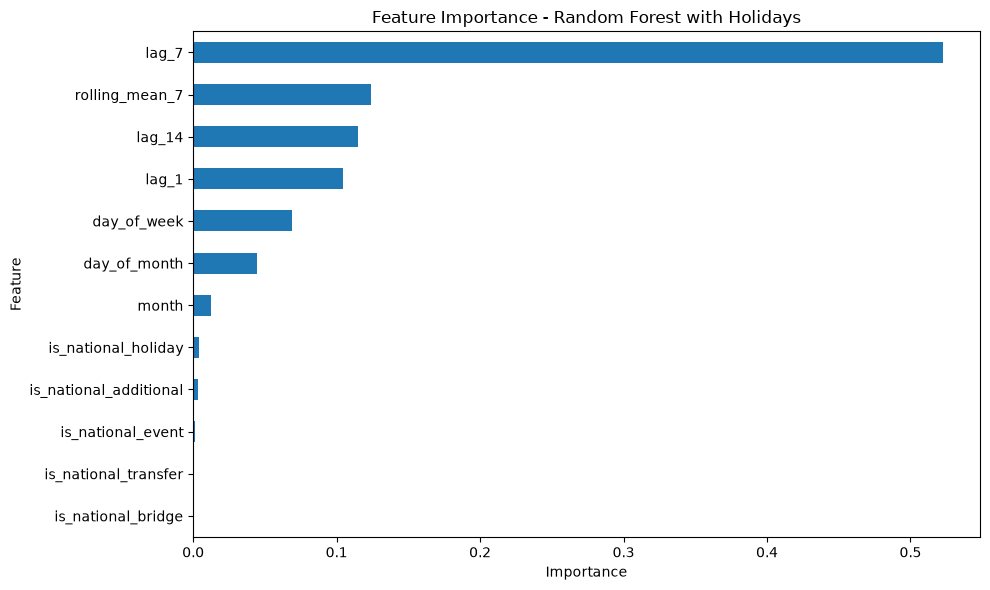

In [59]:
holiday_importance = pd.DataFrame({
    "feature": features_holidays,
    "importance": rf_holiday_model.feature_importances_
}).sort_values("importance", ascending=False)

display(holiday_importance)

# Visualize the 12 most important features
holiday_importance.head(12).sort_values(
    "importance"
).plot(
    x="feature",
    y="importance",
    kind="barh",
    figsize=(10, 6),
    legend=False
)

plt.title("Feature Importance - Random Forest with Holidays")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## Feature Importance Interpretation

The feature importance analysis shows that lag_7 is the strongest predictor in the Random Forest model, followed by rolling_mean_7, lag_14, and lag_1.

These results suggest that recent sales history and recurring weekly patterns provide most of the predictive information.

The national holiday indicators have relatively low feature importance, consistent with the small improvement observed after adding them. However, low importance does not necessarily mean holidays have no effect; their contribution may be limited by the daily aggregation and the use of national events only.

## Explore Promotion Patterns

I investigate promotion activity in the original store-level and product-family sales dataset.

I aggregate promotion information by date and compare it with total daily sales to understand whether promotion activity may provide useful predictive information.

This analysis will help determine whether daily promotion features should be tested in the forecasting model.

In [60]:
# Aggregate promotion activity by date from the original dataset
daily_promotions = (
    df.groupby("date", as_index=False)
    .agg(
        total_onpromotion=("onpromotion", "sum"),
        promoted_records=("onpromotion", lambda x: (x > 0).sum())
    )
)

# Ensure dates use the same datetime format
daily_promotions["date"] = pd.to_datetime(daily_promotions["date"])

# Merge promotion data with daily sales
sales_promotions = daily_sales.merge(
    daily_promotions,
    on="date",
    how="left",
    validate="one_to_one"
)

print("Dataset shape:", sales_promotions.shape)
display(sales_promotions.head())

print("\nCorrelation with daily sales:")
display(
    sales_promotions[
        ["sales", "total_onpromotion", "promoted_records"]
    ].corr().round(3)
)

Dataset shape: (1684, 4)


,date,sales,total_onpromotion,promoted_records
0,2013-01-01,2511.618999,0,0
1,2013-01-02,496092.417944,0,0
2,2013-01-03,361461.231124,0,0
3,2013-01-04,354459.677093,0,0
4,2013-01-05,477350.121229,0,0



Correlation with daily sales:


,sales,total_onpromotion,promoted_records
sales,1.000,0.575,0.690
total_onpromotion,0.575,1.000,0.891
promoted_records,0.690,0.891,1.000


In [61]:
print("Sales + promotion columns:")
print(sales_promotions.columns.tolist())

print("\nTraining columns:")
print(train_daily.columns.tolist())

print("\nValidation columns:")
print(valid_daily.columns.tolist())

print("\nExisting model variables:")
print([
    name for name in globals()
    if any(word in name.lower()
           for word in ["model", "rf", "mae", "rmse", "prediction"])
])

Sales + promotion columns:
['date', 'sales', 'total_onpromotion', 'promoted_records']

Training columns:
['date', 'sales']

Validation columns:
['date', 'sales', 'baseline_prediction']

Existing model variables:
['mae', 'rmse', 'model_df', 'train_model', 'valid_model', 'rf_model', 'predictions', 'mae_rf', 'rmse_rf', 'model_df_holidays', 'train_model_holidays', 'valid_model_holidays', 'rf_holiday_model', 'predictions_holidays', 'mae_holiday', 'rmse_holiday']


## Prepare the Promotion Dataset

In [62]:
# Create a separate dataset for the promotion experiment
promotion_df = sales_promotions.copy()

promotion_df["date"] = pd.to_datetime(promotion_df["date"])
promotion_df = promotion_df.sort_values("date").reset_index(drop=True)

# Use the same chronological split as the existing daily dataset
split_date_promo = train_daily["date"].max()

train_promo = promotion_df[
    promotion_df["date"] <= split_date_promo
].copy()

valid_promo = promotion_df[
    promotion_df["date"] > split_date_promo
].copy()

print("Training rows:", len(train_promo))
print("Validation rows:", len(valid_promo))
print("Training ends:", train_promo["date"].max())
print("Validation starts:", valid_promo["date"].min())

Training rows: 1347
Validation rows: 337
Training ends: 2016-09-11 00:00:00
Validation starts: 2016-09-12 00:00:00


## Training Promotion Model

In [63]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

promo_features = ["total_onpromotion", "promoted_records"]

X_train_promo = train_promo[promo_features].fillna(0)
y_train_promo = train_promo["sales"]

X_valid_promo = valid_promo[promo_features].fillna(0)
y_valid_promo = valid_promo["sales"]

rf_promo_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_promo_model.fit(X_train_promo, y_train_promo)

predictions_promo = rf_promo_model.predict(X_valid_promo)

mae_promo = mean_absolute_error(y_valid_promo, predictions_promo)
rmse_promo = np.sqrt(
    mean_squared_error(y_valid_promo, predictions_promo)
)

print("Promotion Model MAE:", round(mae_promo, 2))
print("Promotion Model RMSE:", round(rmse_promo, 2))

Promotion Model MAE: 147353.94
Promotion Model RMSE: 189959.77


## Comparing Model Performance

In [64]:
comparison = pd.DataFrame({
    "Model": [
        "Baseline",
        "Random Forest",
        "Random Forest + Holidays",
        "Promotion-only Random Forest"
    ],
    "MAE": [
        mae,
        mae_rf,
        mae_holiday,
        mae_promo
    ],
    "RMSE": [
        rmse,
        rmse_rf,
        rmse_holiday,
        rmse_promo
    ]
})

display(comparison.round(2))

,Model,MAE,RMSE
0,Baseline,267597.91,321869.46
1,Random Forest,77640.95,122620.00
2,Random Forest + Holidays,77083.00,122154.26
3,Promotion-only Random Forest,147353.94,189959.77


## Feature Importance

In [65]:
print("Available model variables:")
for name in [
    "rf_model", "train_model", "model_df",
    "valid_model", "predictions", "predictions_holiday"
]:
    if name in globals():
        print(name, "->", type(globals()[name]).__name__)

print("\nAvailable DataFrames:")
for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        print(name, "->", obj.shape)

Available model variables:
rf_model -> RandomForestRegressor
train_model -> DataFrame
model_df -> DataFrame
valid_model -> DataFrame
predictions -> ndarray

Available DataFrames:
_ -> (5, 2)
___ -> (8, 4)
df -> (3000888, 6)
_8 -> (8, 4)
_12 -> (8, 4)
quality_report -> (6, 4)
daily_sales -> (1684, 2)
train_daily -> (1347, 2)
valid_daily -> (337, 3)
_34 -> (5, 2)
model_df -> (1670, 9)
train_model -> (1333, 9)
valid_model -> (337, 9)
X_train -> (1333, 7)
X_valid -> (337, 7)
importance_df -> (7, 2)
results -> (337, 4)
temp -> (1684, 4)
error_analysis -> (337, 5)
holidays -> (350, 6)
holiday_work -> (350, 6)
active_holidays -> (338, 6)
national_events -> (166, 6)
holiday_features -> (1684, 7)
daily_sales_holidays -> (1684, 8)
model_df_holidays -> (1670, 15)
train_model_holidays -> (1333, 15)
valid_model_holidays -> (337, 15)
X_train_holidays -> (1333, 13)
X_valid_holidays -> (337, 13)
comparison -> (4, 3)
holiday_importance -> (13, 2)
daily_promotions -> (1684, 3)
sales_promotions -> (1684,

In [66]:
print("rf_model:", "rf_model" in globals())
print("model_df:", "model_df" in globals())
print("predictions:", "predictions" in globals())

rf_model: True
model_df: True
predictions: True


## Actual vs Predicted Sales Chart

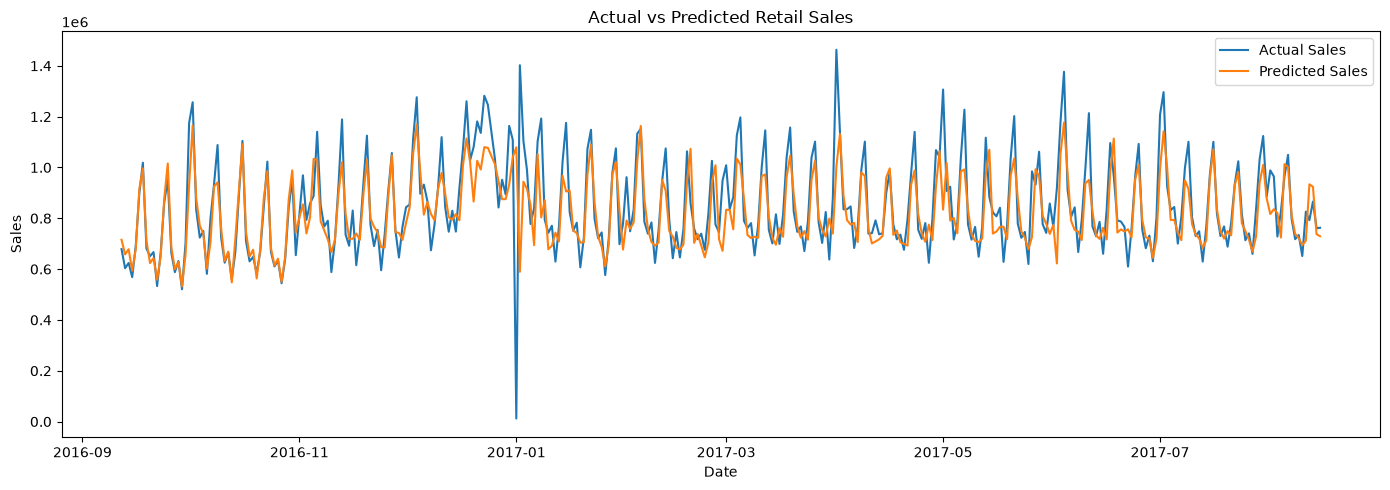

In [67]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    valid_model["date"],
    valid_model["sales"],
    label="Actual Sales"
)

plt.plot(
    valid_model["date"],
    predictions,
    label="Predicted Sales"
)

plt.title("Actual vs Predicted Retail Sales")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.tight_layout()
plt.show()

## Error Analysis

,Actual Sales,Predicted Sales,Error,Absolute Error
0,6.787765e+05,715301.460817,-36525.001690,36525.001690
1,6.034279e+05,657853.597930,-54425.650956,54425.650956
2,6.242621e+05,678134.589205,-53872.517229,53872.517229
3,5.683248e+05,593624.347526,-25299.534540,25299.534540
4,6.919126e+05,678632.438905,13280.162561,13280.162561
5,8.992193e+05,914740.429135,-15521.131627,15521.131627
6,1.018663e+06,996364.935791,22297.721603,22297.721603
7,6.811593e+05,712870.639244,-31711.297268,31711.297268
8,6.509803e+05,623757.605199,27222.716773,27222.716773
9,6.669284e+05,643312.146498,23616.253515,23616.253515


Mean Absolute Error: 77640.95
Root Mean Squared Error: 122620.0


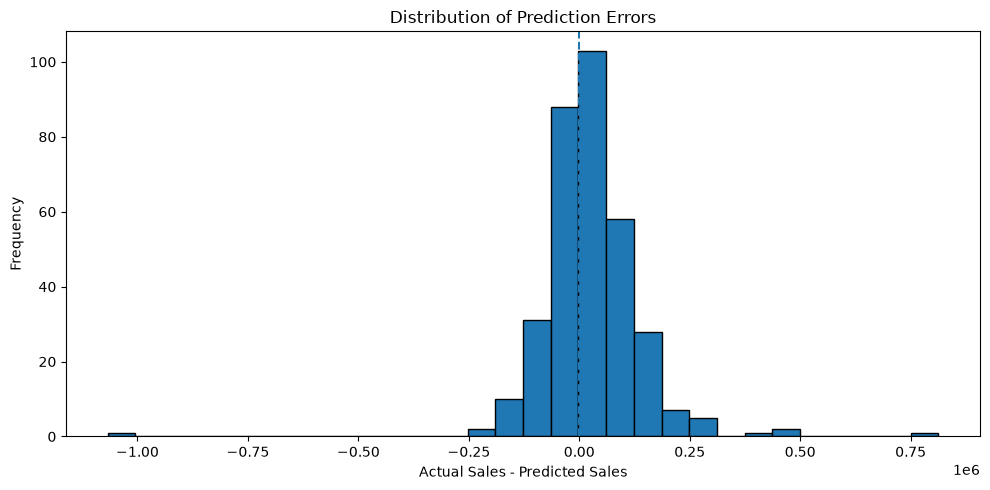

In [68]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

actual = valid_model["sales"].to_numpy()
predicted = np.asarray(predictions)

errors = actual - predicted

error_summary = pd.DataFrame({
    "Actual Sales": actual,
    "Predicted Sales": predicted,
    "Error": errors,
    "Absolute Error": np.abs(errors)
})

display(error_summary.head(10))

print("Mean Absolute Error:", round(np.mean(np.abs(errors)), 2))
print("Root Mean Squared Error:", round(np.sqrt(np.mean(errors ** 2)), 2))

plt.figure(figsize=(10, 5))
plt.hist(errors, bins=30, edgecolor="black")
plt.axvline(0, linestyle="--")
plt.title("Distribution of Prediction Errors")
plt.xlabel("Actual Sales - Predicted Sales")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

## Final Validation & Leakage check

In [69]:
print("Training period:")
print(train_model["date"].min(), "to", train_model["date"].max())

print("\nValidation period:")
print(valid_model["date"].min(), "to", valid_model["date"].max())

print("\nTraining rows:", len(train_model))
print("Validation rows:", len(valid_model))
print("Predictions:", len(predictions))

print(
    "\nValidation starts after training:",
    valid_model["date"].min() > train_model["date"].max()
)

print(
    "Prediction length matches validation:",
    len(predictions) == len(valid_model)
)

Training period:
2013-01-15 00:00:00 to 2016-09-11 00:00:00

Validation period:
2016-09-12 00:00:00 to 2017-08-15 00:00:00

Training rows: 1333
Validation rows: 337
Predictions: 337

Validation starts after training: True
Prediction length matches validation: True


## Conclusion

This project developed a retail sales forecasting workflow using historical sales data and machine learning.

### Models Evaluated
- Baseline model
- Random Forest Regressor
- Random Forest with holiday features
- Promotion-only Random Forest

### Best Model
The Random Forest model with holiday features achieved the lowest validation errors among the evaluated approaches.

- **MAE:** 77,083.00
- **RMSE:** 122,154.26

Compared with the baseline, the best model reduced MAE by approximately 71.2%.

### Key Learnings
- Historical sales patterns are useful for forecasting.
- Holiday features provided a small improvement in validation performance.
- Promotion-only features did not perform as well as the full Random Forest approach.
- Time-based validation is important for evaluating forecasting models.

### Limitations and Future Improvements
- Verify that all features are available at prediction time and do not introduce data leakage.
- Evaluate performance across individual stores and product categories.
- Test the selected model on additional time-based validation periods.
- Explore further feature engineering and hyperparameter tuning.

### Final Note
The reported metrics represent validation performance and do not guarantee the same accuracy on future unseen data.